## Цель работы: 
#### освоить распространённые методы кластеризации, пригодные для обработки данных разных типов (числовых и текстовых), а также инструменты для извлечения параметров из текстовых данных.

## Задачи: 
#### требуется выполнить кластеризацию двух самостоятельно сгенерированных выборок входных данных указанных видов. Первая из выборок должна содержать числовые данные(координаты точек) вторая—текстовые данные, для обработки которых требуется предварительно получить набор численных характеристик — признаков. Номера типов входных данных, алгоритмов кластеризации и методов оценки качества кластеризации определяются по номеру варианта из таблицы 1. Пронумерованные описания методов кластеризации, используемых для числовых данных, находятся в таблице 2, методов оценки качества — в таблице 3, генерации численных данных — в таблице 4, текстовых данных — в таблице 5.

#### Полные коды всех разработанных методов должны быть предоставлены для проверки; требуемые пояснения могут быть даны в виде комментариев к коду или отдельным документом любого нужного формата.

## Задание 1. 
#### По номеру варианта определить из таблицы 1 типы входных данных, которые надо программно сгенерировать для дальнейшей обработки, номера алгоритмов, которые следует применить к этим данным, и методы оценки качества результатов. Из таблицы 2 определить используемый алгоритм кластеризации, из таблицы 3 — метод оценки качества.

#### 6 вариант 
#### Алгоритм 2 DBSCAN (sklearn.cluster.DBSCAN)
#### Качество 1,3 Rand Index (sklearn.metrics.rand_score); Silhouette Score (sklearn.metrics.silhouette_score)
#### Точки 3,4 
#### Тексты 2

## Задание 2. 
#### Определить из таблицы 4 виды входных данных, которые должны быть обработаны, и сгенерировать выборку, состоящую из них. В неё должны входить две указанные группы точек пространства без сохранения сведений о номере их типа. Выполнить кластеризацию полученного набора данных несколько раз, изменяя число кластеров (в методах, которые это допускают) либо прочие характеристики близости прецедентов. Оценить устойчивость получаемых результатов при повторных запусках с разными значениями генератора псевдослучайных чисел. Оценить качество результатов всеми нужными методами. Если метод требует наличия эталонной кластеризации, можно взять в качестве номера класса номер группы точек, из которой были сгенерированы примеры из выборки.

3 Точки вида (a, b + ε, 0.5 + a + ε), где значения a, b, ε - независимые случайные числа, нормально распределённые со средним значением 0 и среднеквадратическим отклонением 0.5

4 Точки вида (a, b, −0.5+bε), где значения a, b, ε — независимые случайные числа, нормально распределённые со средним значением 0 и среднеквадратическим отклонением 0.5

In [12]:
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.cluster import DBSCAN

In [22]:
from numpy.random import permutation


def generate_cluster_data(n_samples_per_type=500, random_state=None):
    """
    Генерирует выборку точек для задачи кластеризации.
    
    Параметры:
    ----------
    n_samples_per_type : int
        Количество точек каждого типа (итоговый размер выборки = 2 * n_samples_per_type).
    random_state : int или None
        Зерно генератора случайных чисел для воспроизводимости.
        
    Возвращает:
    -------
    X : np.ndarray формы (2 * n_samples_per_type, 3)
        Массив 3D-точек в случайном порядке.
    """
    rng = np.random.default_rng(random_state)
    mean = 0.0
    std = 0.5
    
    # 1. Точки первого типа: (a, b + eps, 0.5 + a + eps)
    a1 = rng.normal(mean, std, size=n_samples_per_type)
    b1 = rng.normal(mean, std, size=n_samples_per_type)
    eps1 = rng.normal(mean, std, size=n_samples_per_type)
    
    type1 = np.column_stack([
        a1,
        b1 + eps1,
        0.5 + a1 + eps1
    ])
    y1 = np.zeros(n_samples_per_type, dtype=int)
    
    # 2. Точки второго типа: (a, b, -0.5 + b * eps)
    a2 = rng.normal(mean, std, size=n_samples_per_type)
    b2 = rng.normal(mean, std, size=n_samples_per_type)
    eps2 = rng.normal(mean, std, size=n_samples_per_type)
    
    type2 = np.column_stack([
        a2,
        b2,
        -0.5 + b2 * eps2
    ])
    y2 = np.ones(n_samples_per_type, dtype=int)
    
    # Объединение типов и перемешивание порядка точек
    X = np.vstack([type1, type2])
    y = np.concatenate([y1, y2])
    
    permutation = rng.permutation(len(X))
    X = X[permutation]
    y = y[permutation]
    
    return X, y

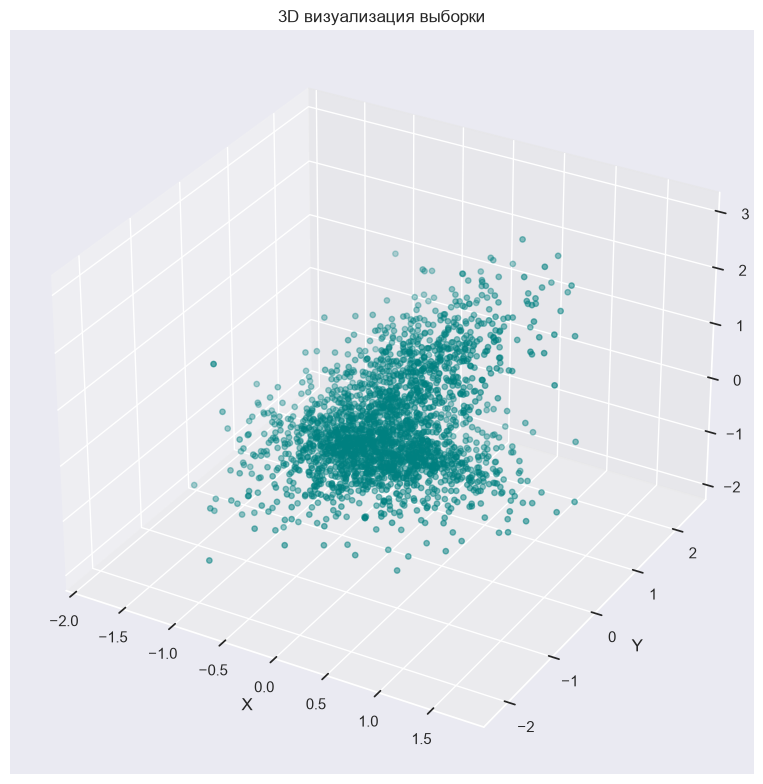

In [68]:
# Используем исходную функцию, возвращающую перемешанный массив X
X, y = generate_cluster_data(n_samples_per_type=1200, random_state=42)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Отрисовка всех точек
ax.scatter(X[:, 0], X[:, 1], X[:, 2], alpha=0.8, c='teal', s=15)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('3D визуализация выборки')

plt.tight_layout()
plt.savefig(fname= '3d viz.png')
plt.show()

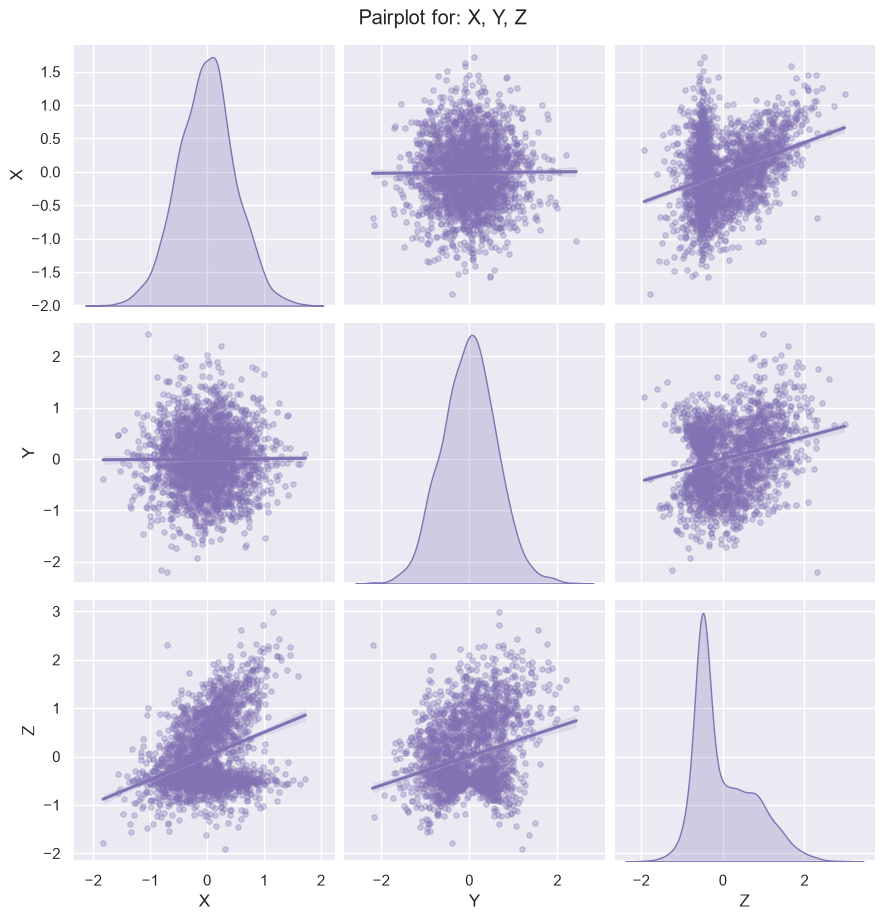

In [27]:
def generate_g(df: pd.DataFrame, columns: list, df_name: str) -> None:
    sns.set_theme(style="darkgrid")
    grid = sns.pairplot(
        df[columns], 
        kind="reg", 
        diag_kind='kde', 
        plot_kws={
            'line_kws': {'color': 'm'}, 
            'scatter_kws': {'color': 'm', 'alpha': 0.3, 's': 15}
        },
        diag_kws={'color': 'm', 'fill': True},
        height=3
    )
    grid.fig.suptitle(f"Pairplot for: {', '.join(columns)}", y=1.02)

    file_name = f"data_visualization_{df_name}.png"
    grid.savefig(fname=file_name, bbox_inches='tight')
    plt.show()

data = generate_cluster_data(n_samples_per_type=500, random_state=42)

df = pd.DataFrame(X, columns=['X', 'Y', 'Z'])

# 3. Вызываем функцию визуализации
generate_g(df, columns=['X', 'Y', 'Z'], df_name='cluster_data')

In [19]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import rand_score
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [38]:
metrics = [rand_score,silhouette_score]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
n_samples = list(range(2, 20))
eps = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for sample in n_samples:
    for ep in eps:
        model = DBSCAN(eps = ep, min_samples= sample, metric = 'euclidean')
        labels = model.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_ratio = np.mean(labels == -1)

        if n_clusters >=2:
            sil_score = silhouette_score(X_scaled, labels)
        else:
            sil_score = None
        r_score = rand_score(y, labels)

        results.append({
            'eps': ep,
            'min_samples': sample,
            'n_clusters': n_clusters,
            'noise_ratio': noise_ratio,
            'noise_ratio': noise_ratio,
            'silhouette_score': sil_score,
            'r_score': r_score
        })
df_results = pd.DataFrame(results)
print(df_results)

        

     eps  min_samples  n_clusters  noise_ratio  silhouette_score   r_score
0    0.1            2         231     0.661667         -0.451978  0.527222
1    0.2            2         161     0.237083         -0.340680  0.585023
2    0.3            2          59     0.079167         -0.434207  0.501145
3    0.4            2          37     0.039583         -0.322102  0.500457
4    0.5            2          13     0.018750         -0.074657  0.499909
..   ...          ...         ...          ...               ...       ...
121  0.3           19           4     0.605000         -0.181917  0.639635
122  0.4           19           1     0.272083               NaN  0.516452
123  0.5           19           1     0.118333               NaN  0.503128
124  0.6           19           1     0.056667               NaN  0.500527
125  0.7           19           1     0.033750               NaN  0.500170

[126 rows x 6 columns]


In [40]:
# Фильтруем результаты: хотим от 2 кластеров и не более 30% шума
valid_results = df_results[
    (df_results['n_clusters'] >= 2) & 
    (df_results['noise_ratio'] < 0.30)
]

print("--- top 5 r_score---")
top_r = valid_results.sort_values(by='r_score', ascending=False).head(5)
print(top_r.to_string(index=False))

print("\n--- top 5 silh_score --------------------------------------")
top_sil = valid_results.sort_values(by='silhouette_score', ascending=False).head(5)
print(top_sil.to_string(index=False))

--- top 5 r_score---
 eps  min_samples  n_clusters  noise_ratio  silhouette_score  r_score
 0.2            2         161     0.237083         -0.340680 0.585023
 0.3            8           5     0.284583         -0.349655 0.515970
 0.3            7           8     0.241250         -0.289853 0.511042
 0.3            6           9     0.202917         -0.241803 0.507541
 0.3            5          11     0.175417         -0.358514 0.505976

--- top 5 silh_score --------------------------------------
 eps  min_samples  n_clusters  noise_ratio  silhouette_score  r_score
 0.7            2           2     0.003750          0.416361 0.499794
 0.7            5           2     0.007083          0.393742 0.499802
 0.6            5           2     0.021250          0.359302 0.499874
 0.5            4           2     0.032083          0.338507 0.499980
 0.5            5           2     0.038750          0.326157 0.500049


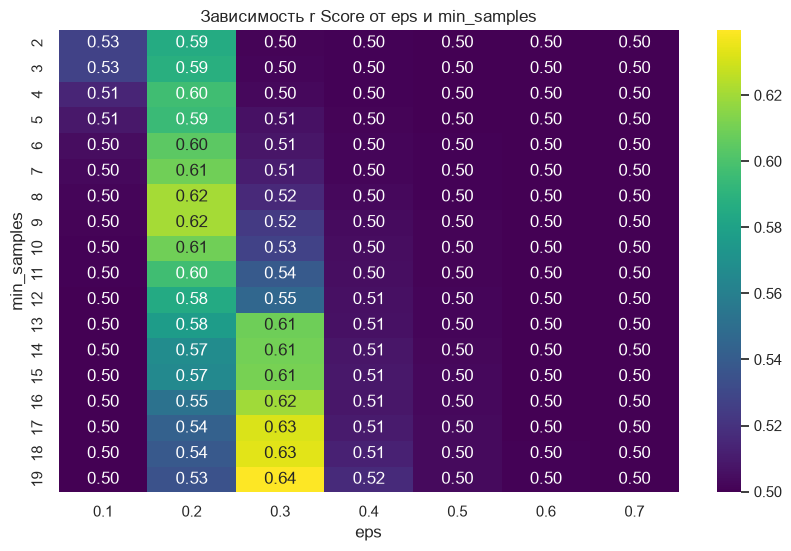

In [44]:
# Сводная таблица для тепловой карты по r_score
pivot_ari = df_results.pivot(index='min_samples', columns='eps', values='r_score')

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_ari, annot=True, fmt=".2f", cmap="viridis")
plt.title("Зависимость r Score от eps и min_samples")
plt.xlabel("eps")
plt.ylabel("min_samples")
plt.savefig(fname = 'heatmap_r_score.png')
plt.show()

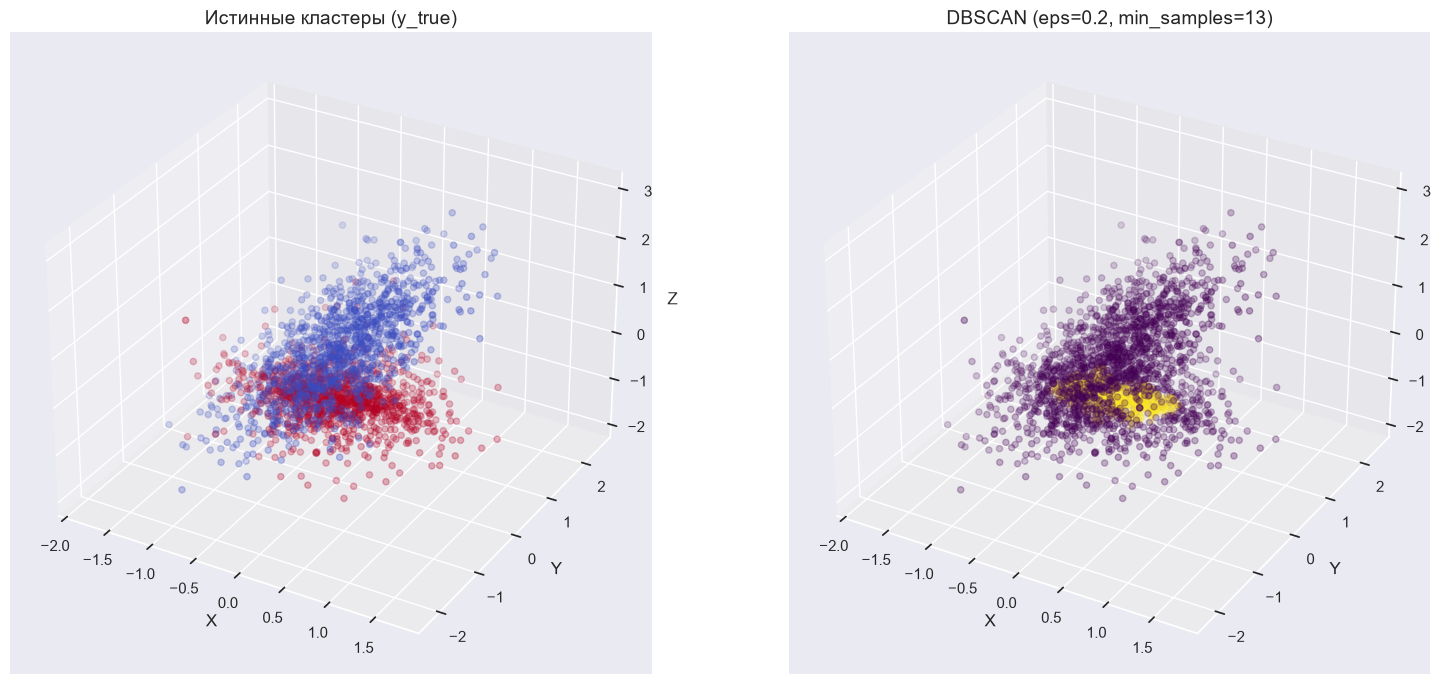


Распределение точек по кластерам (метка -1 означает шум):
  Шум (Outliers): 1894 точек
  Кластер 0: 506 точек


In [69]:
best_eps = 0.2
best_min_samples = 13

best_model = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric='euclidean')
predicted_labels = best_model.fit_predict(X_scaled)

fig = plt.figure(figsize=(16, 7))

# График 1: Истинные кластеры (y_true)
ax1 = fig.add_subplot(121, projection='3d')
scatter1 = ax1.scatter(
    X[:, 0], X[:, 1], X[:, 2], 
    c=y, cmap='coolwarm', alpha=0.6, s=20
)
ax1.set_title('Истинные кластеры (y_true)', fontsize=14)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

# График 2: Кластеры, найденные DBSCAN
ax2 = fig.add_subplot(122, projection='3d')
# DBSCAN помечает шум как -1, отрисуем его отдельной палитрой
scatter2 = ax2.scatter(
    X[:, 0], X[:, 1], X[:, 2], 
    c=predicted_labels, cmap='viridis', alpha=0.6, s=20
)
ax2.set_title(f'DBSCAN (eps={best_eps}, min_samples={best_min_samples})', fontsize=14)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')

plt.tight_layout()
plt.savefig(fname = 'true_vs_dbscan.png')
plt.show()

# --- 4. Оценка распределения найденных меток ---
unique_labels, counts = np.unique(predicted_labels, return_counts=True)
print("\nРаспределение точек по кластерам (метка -1 означает шум):")
for label, count in zip(unique_labels, counts):
    cluster_name = "Шум (Outliers)" if label == -1 else f"Кластер {label}"
    print(f"  {cluster_name}: {count} точек")

Замечание:
Второй тип точек ($z = -0.5 + b\epsilon$) имеет мультипликативный шум $b \cdot \epsilon$. Чем дальше точка уходит по оси $Y$ (параметр $b$), тем сильнее разброс по оси $Z$. Плотность точек на периферии резко падает, и плотностной алгоритм DBSCAN начинает считать эти «редкие» точки выбросами.Первый тип точек ($z = 0.5 + a + \epsilon$) образует наклонную плоскость с нормальным разбросом, но в центре (около $a=0, b=0$) оба типа сильно пересекаются. DBSCAN видит там непрерывную область высокой плотности и склеивает их в один единственный кластер.Поскольку один из классов не имеет фиксированной плотности, DBSCAN не подходит для этой задачи геометрической кластеризации.

Для кластеризация лучше подошла бы смесь гауссиан

In [71]:
X, y = generate_cluster_data(n_samples_per_type=1200, random_state=18)

     eps  min_samples  n_clusters  noise_ratio  silhouette_score   r_score
0    0.1            2         230     0.650000         -0.431602  0.524937
1    0.2            2         180     0.227917         -0.390304  0.554504
2    0.3            2          60     0.077917         -0.423622  0.502258
3    0.4            2          27     0.036667         -0.322151  0.500274
4    0.5            2          12     0.017500          0.011622  0.499991
..   ...          ...         ...          ...               ...       ...
121  0.3           19           5     0.565417         -0.237347  0.637281
122  0.4           19           1     0.270833               NaN  0.527809
123  0.5           19           1     0.125417               NaN  0.503477
124  0.6           19           1     0.061250               NaN  0.500695
125  0.7           19           1     0.037500               NaN  0.500147

[126 rows x 6 columns]
--- top 5 r_score---
 eps  min_samples  n_clusters  noise_ratio  silhouette_

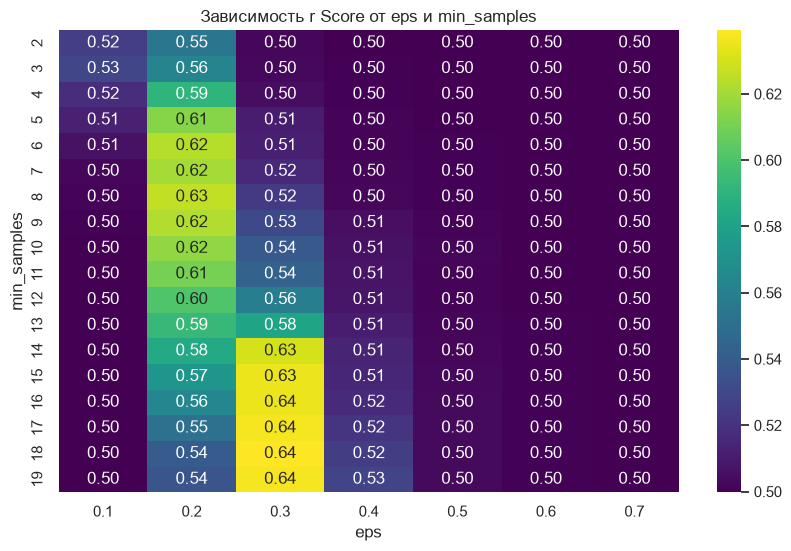

In [72]:
metrics = [rand_score,silhouette_score]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
n_samples = list(range(2, 20))
eps = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for sample in n_samples:
    for ep in eps:
        model = DBSCAN(eps = ep, min_samples= sample, metric = 'euclidean')
        labels = model.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_ratio = np.mean(labels == -1)

        if n_clusters >=2:
            sil_score = silhouette_score(X_scaled, labels)
        else:
            sil_score = None
        r_score = rand_score(y, labels)

        results.append({
            'eps': ep,
            'min_samples': sample,
            'n_clusters': n_clusters,
            'noise_ratio': noise_ratio,
            'noise_ratio': noise_ratio,
            'silhouette_score': sil_score,
            'r_score': r_score
        })
df_results = pd.DataFrame(results)
print(df_results)

# Фильтруем результаты: хотим от 2 кластеров и не более 30% шума
valid_results = df_results[
    (df_results['n_clusters'] >= 2) & 
    (df_results['noise_ratio'] < 0.30)
]

print("--- top 5 r_score---")
top_r = valid_results.sort_values(by='r_score', ascending=False).head(5)
print(top_r.to_string(index=False))

print("\n--- top 5 silh_score --------------------------------------")
top_sil = valid_results.sort_values(by='silhouette_score', ascending=False).head(5)

print(top_sil.to_string(index=False))

# Сводная таблица для тепловой карты по r_score
pivot_ari = df_results.pivot(index='min_samples', columns='eps', values='r_score')

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_ari, annot=True, fmt=".2f", cmap="viridis")
plt.title("Зависимость r Score от eps и min_samples")
plt.xlabel("eps")
plt.ylabel("min_samples")
plt.savefig(fname = 'heatmap_r_score_seed_18.png')
plt.show()

Заметим, что получаемые результаты в зависимости от генерации псевдослучайных чисел - различны: качество метрики отличается для различных гиперпараметров

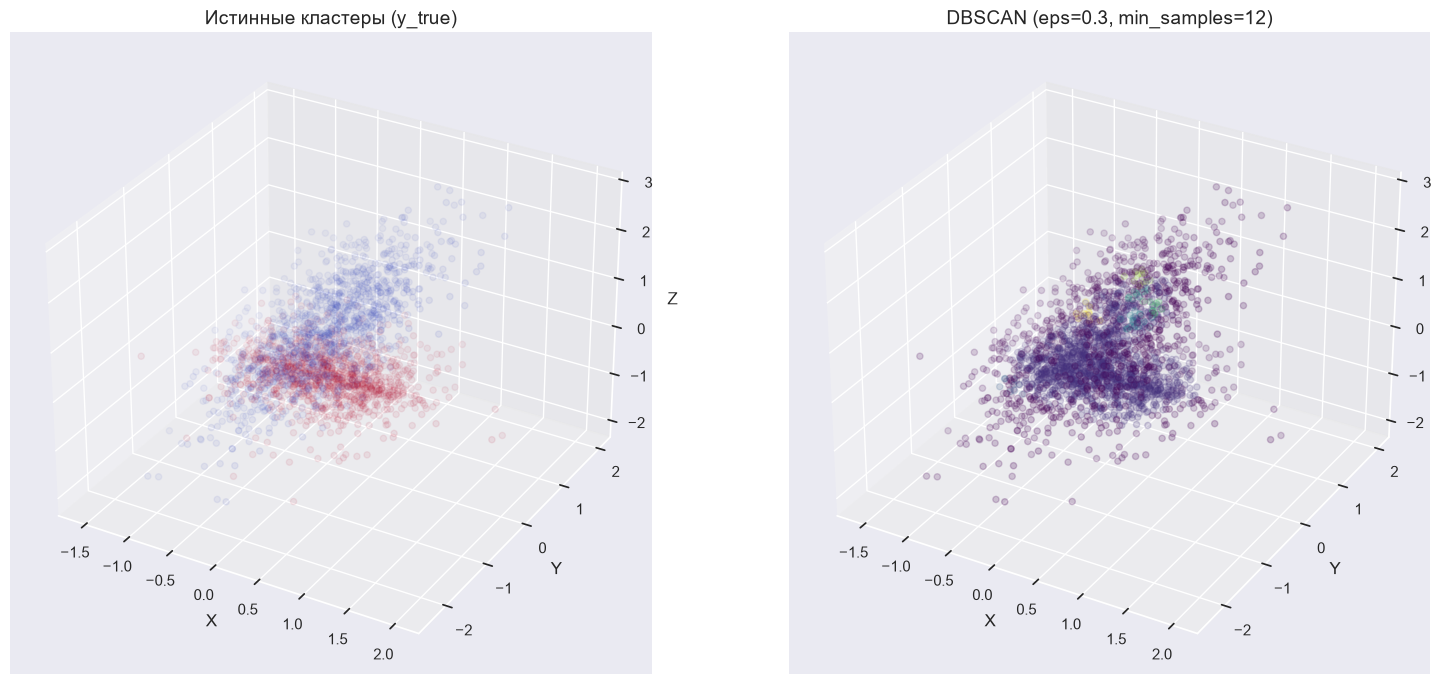


Распределение точек по кластерам (метка -1 означает шум):
  Шум (Outliers): 917 точек
  Кластер 0: 1416 точек
  Кластер 1: 9 точек
  Кластер 2: 17 точек
  Кластер 3: 10 точек
  Кластер 4: 9 точек
  Кластер 5: 12 точек
  Кластер 6: 10 точек


In [81]:
best_eps = 0.3
best_min_samples = 12

best_model = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric='euclidean')
predicted_labels = best_model.fit_predict(X_scaled)

fig = plt.figure(figsize=(16, 7))

# График 1: Истинные кластеры (y_true)
ax1 = fig.add_subplot(121, projection='3d')
scatter1 = ax1.scatter(
    X[:, 0], X[:, 1], X[:, 2], 
    c=y, cmap='coolwarm', alpha=0.3, s=20
)
ax1.set_title('Истинные кластеры (y_true)', fontsize=14)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

# График 2: Кластеры, найденные DBSCAN
ax2 = fig.add_subplot(122, projection='3d')
# DBSCAN помечает шум как -1, отрисуем его отдельной палитрой
scatter2 = ax2.scatter(
    X[:, 0], X[:, 1], X[:, 2], 
    c=predicted_labels, cmap='viridis', alpha=0.5, s=20
)
ax2.set_title(f'DBSCAN (eps={best_eps}, min_samples={best_min_samples})', fontsize=14)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')

plt.tight_layout()
plt.savefig(fname = 'true_vs_dbscan_seed_18.png')
plt.show()

# --- 4. Оценка распределения найденных меток ---
unique_labels, counts = np.unique(predicted_labels, return_counts=True)
print("\nРаспределение точек по кластерам (метка -1 означает шум):")
for label, count in zip(unique_labels, counts):
    cluster_name = "Шум (Outliers)" if label == -1 else f"Кластер {label}"
    print(f"  {cluster_name}: {count} точек")

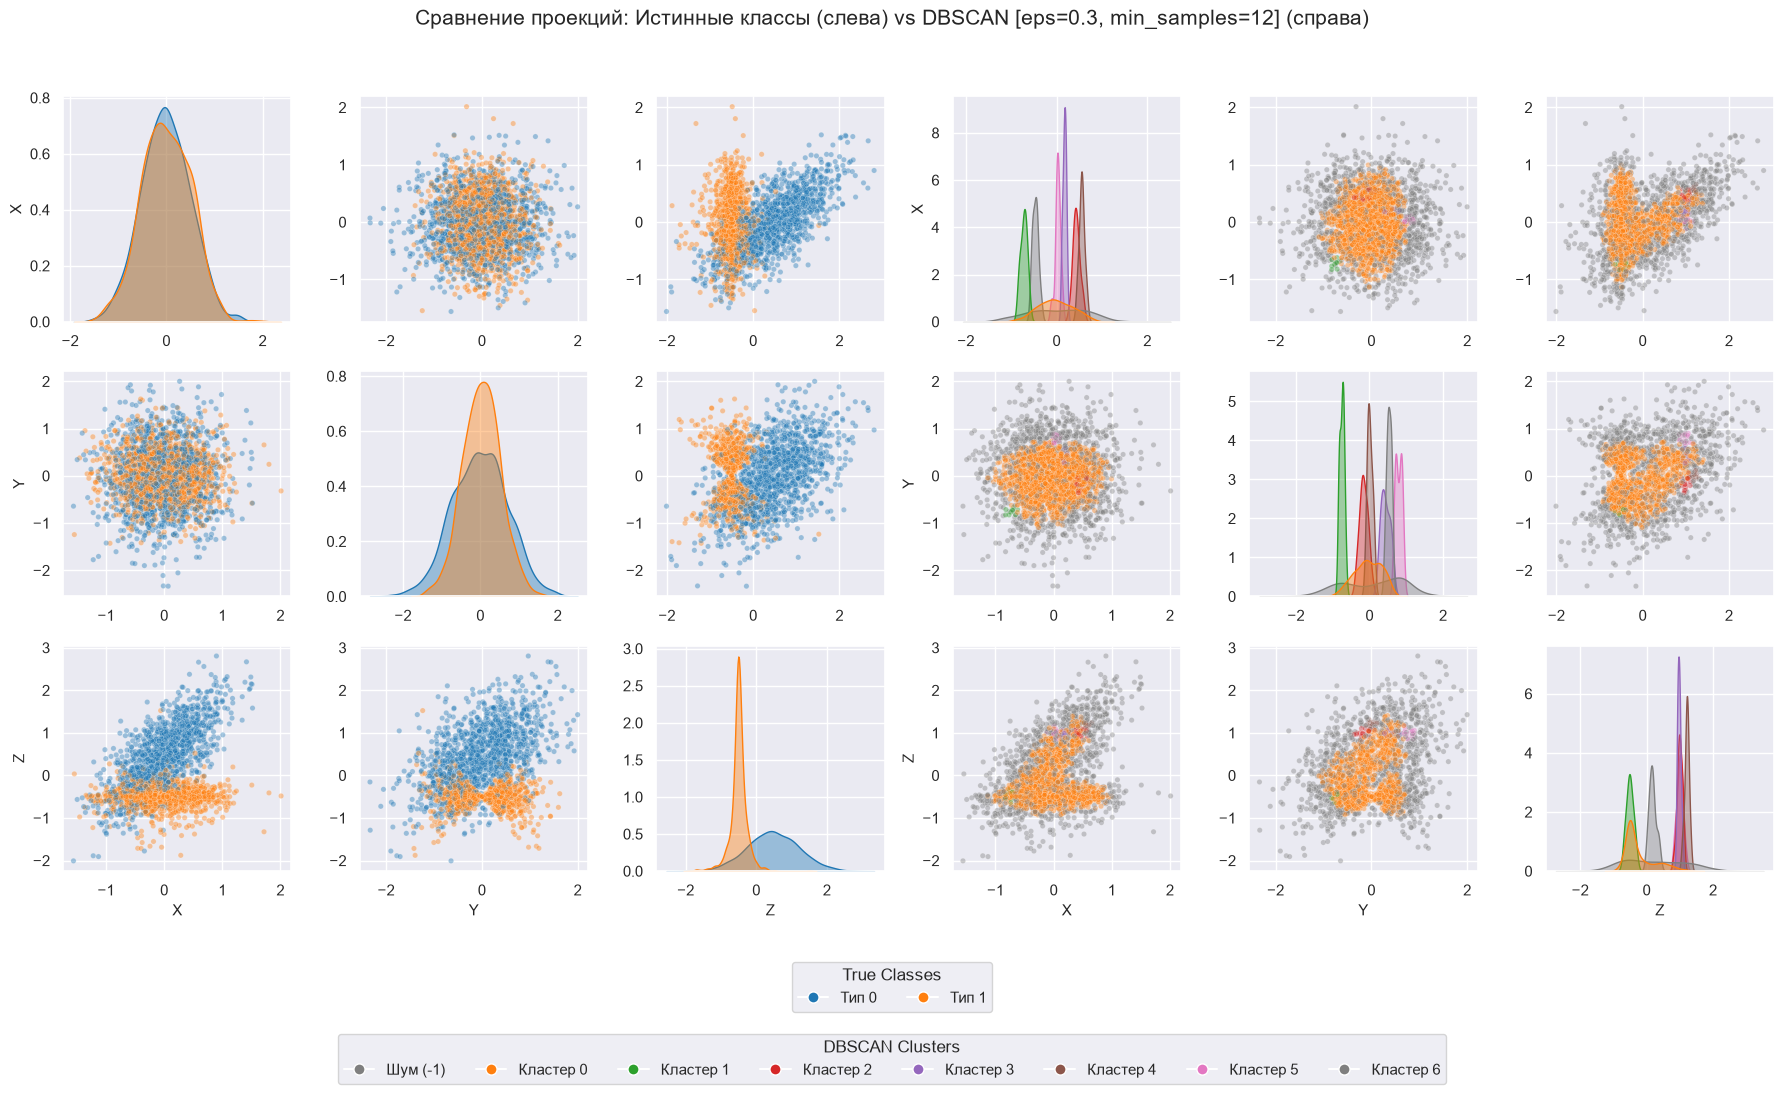

In [87]:
# --- 1. Обучение DBSCAN с лучшими параметрами ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

best_model = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric='euclidean')
y_pred = best_model.fit_predict(X_scaled)

# --- 2. Создание DataFrame ---
df_true = pd.DataFrame(X, columns=['X', 'Y', 'Z'])
df_true['Label'] = y.astype(str)

df_pred = pd.DataFrame(X, columns=['X', 'Y', 'Z'])
df_pred['Label'] = y_pred.astype(str)

# --- 3. Настройка палитр цветов ---
palette_true = {'0': '#1f77b4', '1': '#ff7f0e'}

# Динамическая палитра для DBSCAN (поддерживает любое число кластеров + шум -1)
unique_pred_labels = np.unique(y_pred)
color_list = sns.color_palette('tab10', len(unique_pred_labels))
palette_pred = {}

for i, label in enumerate(unique_pred_labels):
    if label == -1:
        palette_pred['-1'] = '#7f7f7f'  # Серый цвет для шума
    else:
        palette_pred[str(label)] = color_list[i]

# --- 4. Отрисовка проекций (Слева — True, Справа — DBSCAN) ---
sns.set_theme(style="darkgrid")
features = ['X', 'Y', 'Z']
n_feat = len(features)

fig, axes = plt.subplots(n_feat, n_feat * 2, figsize=(18, 9))

for i, row_var in enumerate(features):
    for j, col_var in enumerate(features):
        ax_left = axes[i, j]            # Истинные классы
        ax_right = axes[i, j + n_feat]  # Предсказания DBSCAN
        
        if i == j:
            # Распределение плотности (KDE)
            sns.kdeplot(data=df_true, x=row_var, hue='Label', ax=ax_left, 
                        palette=palette_true, fill=True, common_norm=False, alpha=0.4, legend=False)
            sns.kdeplot(data=df_pred, x=row_var, hue='Label', ax=ax_right, 
                        palette=palette_pred, fill=True, common_norm=False, alpha=0.4, legend=False)
        else:
            # Точечные диаграммы рассеяния (Scatter)
            sns.scatterplot(data=df_true, x=col_var, y=row_var, hue='Label', ax=ax_left, 
                            palette=palette_true, alpha=0.4, s=15, legend=False)
            sns.scatterplot(data=df_pred, x=col_var, y=row_var, hue='Label', ax=ax_right, 
                            palette=palette_pred, alpha=0.4, s=15, legend=False)
        
        # Подписи осей
        if i == n_feat - 1:
            ax_left.set_xlabel(col_var, fontsize=11)
            ax_right.set_xlabel(col_var, fontsize=11)
        else:
            ax_left.set_xlabel('')
            ax_right.set_xlabel('')
            
        ax_left.set_ylabel(row_var if j == 0 else '', fontsize=11)
        ax_right.set_ylabel(row_var if j == 0 else '', fontsize=11)

# Общий заголовок
fig.suptitle(f"Сравнение проекций: Истинные классы (слева) vs DBSCAN [eps={best_eps}, min_samples={best_min_samples}] (справа)", y=1.03, fontsize=15)

# Создаем маркеры для легенд
handles_true = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=8) for c in palette_true.values()]
handles_pred = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=8) for c in palette_pred.values()]
labels_pred_names = [f'Кластер {k}' if k != '-1' else 'Шум (-1)' for k in palette_pred.keys()]

# 1. Верхняя легенда (Истинные классы)
fig.legend(
    handles_true, 
    [f'Тип {k}' for k in palette_true.keys()], 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.02),  # По центру, чуть ниже графика
    ncol=len(palette_true), 
    title="True Classes",
    frameon=True
)

# 2. Ниже стоящая легенда (DBSCAN Clusters)
fig.legend(
    handles_pred, 
    labels_pred_names, 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.10),  # Смещаем ещё ниже по оси Y (-0.10)
    ncol=len(labels_pred_names), 
    title="DBSCAN Clusters",
    frameon=True
)

plt.tight_layout()
plt.show()

## Задание 3. 
#### Определить по таблице 4 вид выборки текстовых данных, после чего самостоятельно собрать её, пользуясь любыми доступными источниками (в том числе, при желании, доступными для свободного использования готовыми выборками). В выборке должно быть по 10 примеров текстов каждого из двух указанных классов. Проще всего использовать англозычные тексты, так как их дальнейшая обработка существенно облегчается благодаря малому числу словоизменений. Размер каждого текста — примерно от 100 до 200–300 слов.
#### Тексты: Десять положительных отзывов на книги либо фильмы и десять отрицательных отзывов на них

## Задание 4. 
#### Кластеризовать текстовую выборку по примеру task4_text_clustering.zip, в котором скрипт test_clustering.py извлекает признаки из текстовой выборки. Допускается использование любого метода извлечения признаков, например:

• sklearn.feature_extraction.text.CountVectorizer;

• sklearn.feature_extraction.text.TfidfVectorizer;

• sklearn.feature_extraction.text.HashingVectorizer.

In [ ]:
# задаём список файлов выборкиClustering of numerical and textual data\model.ipynb

input_neg_files = [
    './rev/movie_reviews/neg/cv000_29416.txt',
    './rev/movie_reviews/neg/cv001_19502.txt',
    './rev/movie_reviews/neg/cv002_17424.txt',
    './rev/movie_reviews/neg/cv003_12683.txt',
    './rev/movie_reviews/neg/cv004_12641.txt',
    './rev/movie_reviews/neg/cv005_29357.txt',
    './rev/movie_reviews/neg/cv006_17022.txt',
    './rev/movie_reviews/neg/cv007_4992.txt',
    './rev/movie_reviews/neg/cv008_29326.txt',
    './rev/movie_reviews/neg/cv009_29417.txt'
]

input_pos_files = [
    './rev/movie_reviews/pos/cv000_29590.txt',
    './rev/movie_reviews/pos/cv001_18431.txt',
    './rev/movie_reviews/pos/cv002_15918.txt',
    './rev/movie_reviews/pos/cv003_11664.txt',
    './rev/movie_reviews/pos/cv004_11636.txt',
    './rev/movie_reviews/pos/cv005_29443.txt',
    './rev/movie_reviews/pos/cv006_15448.txt',
    './rev/movie_reviews/pos/cv007_4968.txt',
    './rev/movie_reviews/pos/cv008_29435.txt',
    './rev/movie_reviews/pos/cv009_29592.txt'
]
# Загрузка текстов из файлов и формирование меток
texts = []
y = []

for file_path in input_neg_files:
    with open(file_path, 'r', encoding='utf-8') as f:
        texts.append(f.read())
        y.append(0)

for file_path in input_pos_files:
    with open(file_path, 'r', encoding='utf-8') as f:
        texts.append(f.read())
        y.append(1)

def fit_model(vectorizers, texts, y):
    for vec in vectorizers:
        model_name = vec.__class__.__name__
        print(f"\n=================== {model_name} ===================")
        
        # Извлечение признаков из текста
        X = vec.fit_transform(texts)
        print(f"Размер матрицы признаков: {X.shape}")
        
        # Обучение модели классификации
        clf = LogisticRegression()
        clf.fit(X, y)
        
        # Предсказание на обучающей выборке
        y_pred = clf.predict(X)
        
        # Сравнение предсказаний с действительными метками
        print("\nМатрица ошибок (Confusion Matrix):")
        print(confusion_matrix(y, y_pred))
        
        print("\nОтчет по классификации (Metrics):")
        print(classification_report(y, y_pred, target_names=['neg (0)', 'pos (1)']))

#Список векторных моделей для сравнения
vectorizers = [
    CountVectorizer(),
    TfidfVectorizer(),
    HashingVectorizer(n_features=2**10)  # Указываем небольшое число признаков для компактности
]

fit_model(vectorizers, texts, y)
        



=================== CountVectorizer ===================
Размер матрицы признаков: (20, 3373)

Матрица ошибок (Confusion Matrix):
[[10  0]
 [ 0 10]]

Отчет по классификации (Metrics):
              precision    recall  f1-score   support

     neg (0)       1.00      1.00      1.00        10
     pos (1)       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20


=================== TfidfVectorizer ===================
Размер матрицы признаков: (20, 3373)

Матрица ошибок (Confusion Matrix):
[[10  0]
 [ 0 10]]

Отчет по классификации (Metrics):
              precision    recall  f1-score   support

     neg (0)       1.00      1.00      1.00        10
     pos (1)       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00

#### Применить для кластеризации метод, применённый в задании 2, и какой-либо другой метод по выбору. Сделать вывод об успешности кластеризации тестовой выборки в таком виде.

In [21]:
def compare_vectorizers_clustering(vectorizers, input_neg_files, input_pos_files):
    # Формируем полный список файлов и целевые метки
    all_rev = input_neg_files + input_pos_files
    y_true = np.array([0] * len(input_neg_files) + [1] * len(input_pos_files))
    
    for vec in vectorizers:
        # Убеждаемся, что векторизатор принимает пути к файлам
        vec.set_params(input='filename')
        model_name = vec.__class__.__name__
        
        print("\n" + "="*60)
        print(f" ВЕКТОРИЗАТОР: {model_name} ")
        print("="*60)
        
        #Извлечение признаков
        X = vec.fit_transform(all_rev)
        print(f"Размер полученной матрицы X: {X.shape}")
        
        # --- Метод 1: KMeans ---
        print("\n--- [1] KMeans ---")
        kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto')
        kmeans_labels = kmeans.fit_predict(X)
        
        print("Полученные кластеры: ", kmeans_labels)
        print("Истинные кластеры:  ", y_true)
        print(f"ARI Score:        {adjusted_rand_score(y_true, kmeans_labels):.4f}")
        print(f"Silhouette Score: {silhouette_score(X, kmeans_labels):.4f}")
        
        # --- Метод 2: DBSCAN ---
        print("\n--- [2] DBSCAN ---")
        dbscan = DBSCAN(eps=0.24, min_samples=2, metric='cosine')
        dbscan_labels = dbscan.fit_predict(X)
        
        print("Полученные кластеры: ", dbscan_labels)
        print("Истинные кластеры:  ", y_true)
        
        # Проверяем количество уникальных кластеров, исключая шум (-1)
        unique_clusters = set(dbscan_labels) - {-1}
        if len(unique_clusters) > 1:
            print(f"ARI Score:        {adjusted_rand_score(y_true, dbscan_labels):.4f}")
            print(f"Silhouette Score: {silhouette_score(X, dbscan_labels):.4f}")
        else:
            print("DBSCAN отнес все объекты к одному кластеру или шуму (-1).")

# Список векторизаторов для тестирования
vectorizers = [
    CountVectorizer(),
    TfidfVectorizer(),
    HashingVectorizer(n_features=2**10)
]

# Запуск функции
compare_vectorizers_clustering(vectorizers, input_neg_files, input_pos_files)


 ВЕКТОРИЗАТОР: CountVectorizer 
Размер полученной матрицы X: (20, 3373)

--- [1] KMeans ---
Полученные кластеры:  [0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0]
Истинные кластеры:   [0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1]
ARI Score:        0.0215
Silhouette Score: 0.2400

--- [2] DBSCAN ---
Полученные кластеры:  [ 0 -1  0  0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0 -1 -1]
Истинные кластеры:   [0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1]
DBSCAN отнес все объекты к одному кластеру или шуму (-1).

 ВЕКТОРИЗАТОР: TfidfVectorizer 
Размер полученной матрицы X: (20, 3373)

--- [1] KMeans ---
Полученные кластеры:  [1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1]
Истинные кластеры:   [0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1]
ARI Score:        0.0000
Silhouette Score: 0.0455

--- [2] DBSCAN ---
Полученные кластеры:  [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
Истинные кластеры:   [0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1]
DBSCAN отнес все объекты к одному кластеру или шуму (-1).

 ВЕКТОРИЗ

#### Попытаться улучшить результаты, вручную повысив сходство текстов каждого из кластеров между собой. Для этого можно, например, добавить в тексты каждой из групп совпадающие слова, заменив ими синонимы. После этого следует повторить кластеризацию, отметить изменения и сделать предположение об их причинах.

In [24]:
#Формируем исходные и модифицированные тексты
texts = []
y_true = np.array([0] * len(input_neg_files) + [1] * len(input_pos_files))

for path in input_neg_files:
    with open(path, 'r', encoding='utf-8') as f:
        texts.append(f.read())

for path in input_pos_files:
    with open(path, 'r', encoding='utf-8') as f:
        texts.append(f.read())

# Усиливаем влияние за счет повторения якорных слов
modified_texts = []
for i, text in enumerate(texts):
    if y_true[i] == 0:
        # Повторяем ключевые слова для создания ощутимого TF-IDF веса
        anchor = " badword terribleword worstword" * 30
    else:
        anchor = " goodword greatword bestword" * 30
    modified_texts.append(text + anchor)

# Функция оценки
def evaluate_clustering(text_data, title):
    # token_pattern гарантирует, что все созданные слова попадают в словарь
    vec = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
    X = vec.fit_transform(text_data)
    
    kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto').fit_predict(X)
    dbscan = DBSCAN(eps=0.6, min_samples=2, metric='cosine').fit_predict(X)
    
    print(f"\n=== {title} ===")
    print(f"KMeans ARI Score:   {adjusted_rand_score(y_true, kmeans):.4f}")
    print(f"DBSCAN ARI Score:   {adjusted_rand_score(y_true, dbscan):.4f}")
    
    if len(set(dbscan) - {-1}) > 1:
        print(f"DBSCAN Silhouette:  {silhouette_score(X, dbscan, metric='cosine'):.4f}")

evaluate_clustering(texts, "ОРИГИНАЛЬНЫЕ ТЕКСТЫ")
evaluate_clustering(modified_texts, "МОДИФИЦИРОВАННЫЕ ТЕКСТЫ")


=== ОРИГИНАЛЬНЫЕ ТЕКСТЫ ===
KMeans ARI Score:   0.0000
DBSCAN ARI Score:   -0.0193

=== МОДИФИЦИРОВАННЫЕ ТЕКСТЫ ===
KMeans ARI Score:   1.0000
DBSCAN ARI Score:   1.0000
DBSCAN Silhouette:  0.5687


## Контрольные вопросы

### 1. Для каких видов данных рассчитать сходство/различие между прецедентами проще, чем значения признаков каждого из них?

### Для данных, у которых нельзя выделить или сложно или много числовых признаков, но можно задать функцию расстояния или метрику. Например, тексты

### 2. Почему кластеризация разными способами может привести к разным результатам?

### Потому что в основе каждой кластеризации собственная эвристика и гипотеза о форме, структуре и плотности кластеров. Например, в случае KMEANS мы задаемся предположением количества кластеров и ищем центры. В случае DBSCAN задаемся предположением соседей и окрестности.

### 3. Как можно оценивать сходство текстов?

### Можно предстаувлять текст в виде вектора countvectorizer/ TF-IDF. 